# CS6362 Assignment 2 · Paper 2 · Figure 3 (F1, C1, C2), revision 2

This is an independent PyTorch implementation based on the supplied paper and assignment PDFs. No author implementation, third-party reproduction, or public review was used. Revision 2 corrects checkpoint recovery and cache validation, adds actual endpoint checks, and makes full logical-batch BatchNorm the default.

**Training and interpolation are disabled by default.** Default Run All executes model shape and synthetic parameter/BN checks only. It does not download data or produce full-dataset reproduction results.

For each architecture, train an SB and LB Adam model, then evaluate
\[
\theta(\alpha)=(1-\alpha)\theta_{SB}+\alpha\theta_{LB},\quad\alpha\in[-1,2].
\]
Alpha 0 is SB and alpha 1 is LB. Plot measured train/test cross entropy on the left axis and train/test classification accuracy (%) on the right, with solid/dashed train/test lines.

| Panel | Data | Paper architecture | SB | Full-data LB |
|---|---|---|---:|---:|
| F1 | MNIST, 60k / 10k | 784 → five BN/ReLU hidden layers of 512 → 10 | 256 | 6,000 |
| C1 | CIFAR-10, 50k / 10k | two stride-2 5×5 conv64/pool3 blocks; dense384/192; BN/ReLU and dense dropout | 256 | 5,000 |
| C2 | CIFAR-10, 50k / 10k | VGG stacks 2×64, 2×128, 3×256, 3×512, 3×512; pool2 after each; dense512; BN/ReLU/dropout | 256 | 5,000 |

### Training protocol and choices

- The paper specifies Adam, the SB/LB sizes above, five trials, and training until loss stops improving. It does not provide all optimizer or architecture details.
- Adam LR `1e-3`, betas `(0.9, 0.999)`, epsilon `1e-8`, no weight decay, and constant LR are explicitly chosen settings. The cap is **100 epochs**, with a training-evaluation CE plateau rule: minimum20 epochs, patience15, min_delta`1e-4`. Reaching the cap is recorded as `max_epochs_censored`, not as author convergence. The endpoint is the best measured training-CE checkpoint under this rule; test performance is not used for selection.
- Start with seed0. SB/LB share initialization within each architecture/seed. One seed cannot estimate the paper's five-trial uncertainty.
- **Default `training_batch_mode='full'`: one complete logical batch is one forward/backward and one Adam update.** The cap256 is inactive here; LB BN sees 5,000/6,000 examples together. Before any endpoints train, each requested model gets one disposable LB training step on the allocated GPU to test peak memory. This is a capacity check, not a reproduction measurement. An OOM stops explicitly; batch sizes are never reduced automatically.
- Optional `training_batch_mode='microbatch'` accumulates sample-weighted gradients with cap256. BN then uses microbatch statistics, so this is a **separate approximation experiment**, not equivalent full-batch BN. Use a separate output root and disclose it. Checkpoint signatures prevent mixing the modes.
- Models retain the first revision's documented choices: C1 conv padding2, pool3/stride2/padding1; C2 same-padded conv3 and pool2/stride2; BN before hidden-layer ReLU; dropout0.5 on C1's two dense hidden layers and C2's dense hidden layer. The output is logits, without output BN/ReLU or a separate softmax. Exact padding/output normalization are implementation assumptions. Appendix B.4's reference to C3 is interpreted as a C2 typo from context.
- `ToTensor` scales pixels into `[0,1]`. No additional crop, normalization, or augmentation is used. This representation scaling is documented because the paper says no image preprocessing.

### Interpolation and validation

Interpolate learned weights/biases and BN affine parameters. At every alpha, reset BN buffers and recalibrate on **training data only**, keeping dropout off, then evaluate full train/test splits in eval mode. `momentum=None` averages calibration-batch moments equally; it is not an exact pooled whole-dataset variance. Calibration batch256 is an explicit, policy-dependent choice because the paper does not specify BN treatment.

Each SB/LB endpoint is independently reloaded and evaluated both before and after BN calibration. Alpha0/1 losses and accuracies must match independently evaluated endpoints **under the same calibration policy** within declared tolerances. Stored raw and recalibrated metrics are reported separately; they are not assumed equal. These checks rerun even when the complete alpha CSV is cached.

New outputs live under `paper2_figure3_outputs_v2/`; v1 results are not read. Every training signature includes training/test content and exact subset identities. Interpolation manifests include endpoint weight/buffer hashes, training signatures, data identities, alpha grid and evaluation policy. Changed endpoints/settings or malformed CSVs are rejected. `last.pt` atomically stores full history and the selected best snapshot; CSV and best files can be rebuilt after interruption. A final saved epoch can be exported to an endpoint without repeating training.

Smoke uses 256/128 examples, SB32/LB128, two epochs and seven alphas. These are software checks, not reproduction results. Full interpolation uses 31 alphas and complete train/test data. The figure is one directional loss slice and does not establish global Hessian sharpness.


## 1. Environment, imports, configuration (no training)

In [1]:
%matplotlib inline
import os, sys, json, math, random, platform, copy, csv, time, hashlib, tempfile
from pathlib import Path
from dataclasses import dataclass, asdict, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

@dataclass(frozen=True)
class Config:
    mode: str = 'smoke'                  # 'smoke' or 'reproduction'
    models: tuple = ('F1', 'C1', 'C2')
    seeds: tuple = (0,)                  # (0,1,2,3,4) for five trials
    root_data: str = os.environ.get('DATA_ROOT', './data')
    root_output: str = os.environ.get('PAPER2_OUTPUT', './paper2_figure3_outputs_v2')
    download_datasets: bool = False     # set True if dataset access is permitted
    small_batch: int = 256
    large_batch_fraction: float = 0.10
    training_batch_mode: str = 'full'   # 'microbatch' is an explicitly different BN experiment
    microbatch_cap: int = 256           # used only in explicit microbatch mode
    run_memory_preflight: bool = True   # disposable full-LB GPU step before any endpoint
    eval_batch: int = 512
    num_workers: int = 2
    lr: float = 1e-3                    # CHOICE, not provided by paper
    betas: tuple = (0.9, 0.999)        # CHOICE
    eps: float = 1e-8                  # CHOICE
    weight_decay: float = 0.0          # CHOICE
    max_epochs: int = 100             # CAP, not author convergence
    min_epochs: int = 20              # CHOICE
    patience: int = 15                # CHOICE
    min_delta: float = 1e-4           # CHOICE in mean train CE
    n_alpha: int = 31                 # CHOICE, [-1,2]
    bn_calibration_batch: int = 256    # CHOICE: cumulative batch moments, training data only
    endpoint_atol: float = 1e-6
    endpoint_rtol: float = 1e-5
    smoke_train_size: int = 256
    smoke_test_size: int = 128
    smoke_small_batch: int = 32
    smoke_large_batch: int = 128
    smoke_max_epochs: int = 2
    smoke_n_alpha: int = 7
    implementation_version: str = 'paper2_fig3_pytorch_v2_verified'

CFG = replace(Config(), mode='reproduction', num_workers=0)
RUN_TRAINING = True
RUN_INTERPOLATION = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

assert CFG.mode in {'smoke', 'reproduction'}
assert CFG.microbatch_cap >= 2
assert CFG.training_batch_mode in {'full', 'microbatch'}
assert CFG.bn_calibration_batch >= 2 and CFG.eval_batch >= 1
assert CFG.max_epochs >= CFG.min_epochs > 0 and CFG.patience > 0
assert len(CFG.models) > 0 and len(CFG.seeds) > 0
assert all(m in {'F1','C1','C2'} for m in CFG.models)
print('Python:', sys.version.split()[0], 'torch:', torch.__version__,
      'torchvision:', torchvision.__version__, 'device:', DEVICE)
print('Host:', platform.node(), 'Slurm job:', os.environ.get('SLURM_JOB_ID', '<none>'))
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0),
          'memory GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
print('Mode:', CFG.mode, '| training enabled:', RUN_TRAINING,
      '| interpolation enabled:', RUN_INTERPOLATION)
print('Training batch mode:', CFG.training_batch_mode, '| GPU memory preflight:', CFG.run_memory_preflight)

assert DEVICE.type == 'cuda', 'A Slurm CUDA GPU is required.'


Python: 3.11.15 torch: 2.11.0+cu128 torchvision: 0.26.0+cu128 device: cuda
Host: ROSALIND-GPU1.vuds.vanderbilt.edu Slurm job: 21735
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition memory GiB: 95.0
Mode: reproduction | training enabled: True | interpolation enabled: True
Training batch mode: full | GPU memory preflight: True


## 2. Models: F1, C1, C2

In [2]:
class F1Net(nn.Module):
    def __init__(self):
        super().__init__()
        layers, n_in = [], 784
        for _ in range(5):
            layers.extend([nn.Linear(n_in, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=False)])
            n_in = 512
        self.features = nn.Sequential(*layers)
        self.output = nn.Linear(512, 10)

    def forward(self, x):
        return self.output(self.features(x.flatten(start_dim=1)))


class C1Net(nn.Module):
    def __init__(self):
        super().__init__()
        blocks, channels = [], 3
        for _ in range(2):
            blocks.extend([
                nn.Conv2d(channels, 64, kernel_size=5, stride=2, padding=2),
                nn.BatchNorm2d(64), nn.ReLU(inplace=False),
                nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
            ])
            channels = 64
        self.conv = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 2 * 2, 384),
            nn.BatchNorm1d(384), nn.ReLU(inplace=False), nn.Dropout(p=0.5),
            nn.Linear(384, 192), nn.BatchNorm1d(192),
            nn.ReLU(inplace=False), nn.Dropout(p=0.5), nn.Linear(192, 10),
        )

    def forward(self, x):
        return self.classifier(self.conv(x))


class C2Net(nn.Module):
    def __init__(self):
        super().__init__()
        stacks = [(64, 2), (128, 2), (256, 3), (512, 3), (512, 3)]
        blocks, channels = [], 3
        for n_out, depth in stacks:
            for _ in range(depth):
                blocks.extend([
                    nn.Conv2d(channels, n_out, kernel_size=3, stride=1, padding=1),
                    nn.BatchNorm2d(n_out), nn.ReLU(inplace=False),
                ])
                channels = n_out
            blocks.append(nn.MaxPool2d(kernel_size=2, stride=2))
        self.conv = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(512, 512), nn.BatchNorm1d(512),
            nn.ReLU(inplace=False), nn.Dropout(p=0.5), nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.classifier(self.conv(x))


def build_model(name):
    if name == 'F1': return F1Net()
    if name == 'C1': return C1Net()
    if name == 'C2': return C2Net()
    raise ValueError(f'Unknown architecture: {name}')


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def shape_audit():
    for name, input_shape, spatial in [
        ('F1', (2, 1, 28, 28), None),
        ('C1', (2, 3, 32, 32), (2, 2)),
        ('C2', (2, 3, 32, 32), (1, 1)),
    ]:
        model = build_model(name).eval()
        with torch.inference_mode():
            x = torch.rand(*input_shape)
            logits = model(x)
            assert logits.shape == (2, 10), (name, tuple(logits.shape))
            if spatial is not None:
                conv = model.conv(x)
                assert tuple(conv.shape[-2:]) == spatial, (name, tuple(conv.shape))
        print(f'{name}: trainable parameters={count_params(model):,}; output={tuple(logits.shape)}' +
              (f'; final conv shape={tuple(conv.shape)}' if spatial else ''))
    print('All synthetic shape checks passed.')

shape_audit()

F1: trainable parameters=1,462,794; output=(2, 10)
C1: trainable parameters=283,274; output=(2, 10); final conv shape=(2, 64, 2, 2)
C2: trainable parameters=14,991,946; output=(2, 10); final conv shape=(2, 512, 1, 1)
All synthetic shape checks passed.


## 3. Dataset loaders and deterministic smoke subsets

In [3]:
TRANSFORM = transforms.ToTensor()  # no dataset-mean/std normalization or augmentation


def get_datasets(name, cfg=CFG):
    root = Path(cfg.root_data)
    klass = datasets.MNIST if name == 'F1' else datasets.CIFAR10
    train = klass(root=str(root), train=True, download=cfg.download_datasets, transform=TRANSFORM)
    test = klass(root=str(root), train=False, download=cfg.download_datasets, transform=TRANSFORM)
    if cfg.mode == 'smoke':
        # Fixed deterministic subset independent of training seed and regime.
        g = torch.Generator().manual_seed(20262027)
        idx_train = torch.randperm(len(train), generator=g)[:cfg.smoke_train_size].tolist()
        idx_test = torch.randperm(len(test), generator=g)[:cfg.smoke_test_size].tolist()
        train, test = Subset(train, idx_train), Subset(test, idx_test)
    else:
        expected = (60000, 10000) if name == 'F1' else (50000, 10000)
        assert (len(train), len(test)) == expected, ('Unexpected dataset split', name)
    return train, test


def batch_sizes(name, n_train, cfg=CFG):
    if cfg.mode == 'smoke':
        small, large = cfg.smoke_small_batch, cfg.smoke_large_batch
    else:
        small, large = cfg.small_batch, int(round(cfg.large_batch_fraction * n_train))
    assert 2 <= small < large <= n_train
    return {'SB': small, 'LB': large}


def make_loader(dataset, batch_size, cfg=CFG, shuffle=False, seed=0):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=cfg.num_workers,
                      pin_memory=(DEVICE.type == 'cuda'),
                      generator=torch.Generator().manual_seed(int(seed)),
                      persistent_workers=(cfg.num_workers > 0))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32 - 1))
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def base_init_seed(name, seed):
    return 10000 + seed * 1000 + {'F1': 101, 'C1': 211, 'C2': 307}[name]


def epoch_shuffle_seed(name, seed, regime, epoch):
    return base_init_seed(name, seed) + epoch * 29 + (0 if regime == 'SB' else 100000)


def run_directory(name, seed, regime, cfg=CFG):
    return Path(cfg.root_output) / cfg.mode / name / f'seed_{seed}' / regime


def _array_digest(value):
    """Hash dtype, shape and bytes without a large temporary bytes copy."""
    if torch.is_tensor(value):
        tensor = value.detach().cpu().contiguous()
        descriptor = {'dtype': str(tensor.dtype), 'shape': list(tensor.shape)}
        array = tensor.reshape(-1).view(torch.uint8).numpy()
    else:
        array = np.ascontiguousarray(np.asarray(value))
        if array.dtype.hasobject:
            raise TypeError('Object arrays need an explicit dataset identity adapter.')
        descriptor = {'dtype': str(array.dtype), 'shape': list(array.shape)}
    digest = hashlib.sha256(json.dumps(descriptor, sort_keys=True).encode())
    view = memoryview(array).cast('B')
    for start in range(0, len(view), 8 * 1024 * 1024):
        digest.update(view[start:start + 8 * 1024 * 1024])
    return digest.hexdigest()


def model_state_hash(state):
    """Include trainable weights and BN buffers, including scalar counters."""
    digest = hashlib.sha256()
    for name in sorted(state):
        digest.update(json.dumps(name).encode())
        digest.update(_array_digest(state[name]).encode())
    return digest.hexdigest()


def dataset_identity(dataset):
    """Content identity for official datasets, TensorDataset and exact subsets."""
    identity = {
        'class': type(dataset).__module__ + '.' + type(dataset).__qualname__,
        'examples': len(dataset),
    }
    if isinstance(dataset, Subset):
        identity['parent'] = dataset_identity(dataset.dataset)
        identity['indices_sha256'] = _array_digest(np.asarray(dataset.indices, dtype=np.int64))
    elif isinstance(dataset, torch.utils.data.TensorDataset):
        identity['tensor_sha256'] = [_array_digest(t) for t in dataset.tensors]
    elif hasattr(dataset, 'data') and hasattr(dataset, 'targets'):
        identity['data_sha256'] = _array_digest(dataset.data)
        identity['targets_sha256'] = _array_digest(dataset.targets)
        identity['transform'] = repr(getattr(dataset, 'transform', None))
        identity['target_transform'] = repr(getattr(dataset, 'target_transform', None))
    else:
        raise TypeError(f'Add a stable content identity adapter for {type(dataset).__name__}.')
    return identity


def atomic_write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', encoding='utf-8',
                                         dir=path.parent, suffix='.json.partial',
                                         delete=False) as handle:
            temporary = Path(handle.name)
            json.dump(value, handle, indent=2, sort_keys=True, allow_nan=False)
            handle.flush()
            os.fsync(handle.fileno())
        os.replace(temporary, path)
        temporary = None
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)


def atomic_write_csv(path, records):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with tempfile.NamedTemporaryFile(mode='w', encoding='utf-8',
                                         dir=path.parent, suffix='.csv.partial',
                                         delete=False, newline='') as handle:
            temporary = Path(handle.name)
            pd.DataFrame.from_records(records).to_csv(handle, index=False)
            handle.flush()
            os.fsync(handle.fileno())
        os.replace(temporary, path)
        temporary = None
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)


def run_signature(name, seed, regime, train_ds, test_ds, cfg=CFG):
    return {
        'implementation_version': cfg.implementation_version,
        'mode': cfg.mode, 'model': name, 'seed': int(seed), 'regime': regime,
        'train_dataset': dataset_identity(train_ds),
        'test_dataset': dataset_identity(test_ds),
        'logical_batch': batch_sizes(name, len(train_ds), cfg)[regime],
        'training_batch_mode': cfg.training_batch_mode,
        'physical_microbatch_cap': cfg.microbatch_cap if cfg.training_batch_mode == 'microbatch' else None,
        'lr': cfg.lr, 'betas': list(cfg.betas), 'eps': cfg.eps,
        'weight_decay': cfg.weight_decay,
        'max_epochs': cfg.smoke_max_epochs if cfg.mode == 'smoke' else cfg.max_epochs,
        'patience': cfg.patience, 'min_delta': cfg.min_delta, 'min_epochs': cfg.min_epochs,
        'shared_init_seed': base_init_seed(name, seed),
        'evaluation_batch': cfg.eval_batch,
    }


print('Dataset access is deferred; signatures include dataset content and exact subset indices.')


Dataset access is deferred; signatures include dataset content and exact subset indices.


## 4. Training/evaluation: full logical-batch BN by default

In [4]:
@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    model.eval()
    loss_total = 0.0
    correct = total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss_total += F.cross_entropy(logits, labels, reduction='sum').item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.numel()
    assert total > 0
    return {'loss': loss_total / total, 'accuracy_pct': 100.0 * correct / total,
            'examples': total}


def train_epoch(model, optimizer, loader, cfg=CFG, device=DEVICE):
    """One Adam update per logical batch; full mode also uses full-batch BN.

    The explicit 'microbatch' alternative changes BN computation and is an
    approximation experiment. It is never selected automatically after an OOM.
    """
    assert cfg.training_batch_mode in {'full', 'microbatch'}
    model.train()
    total_loss, n_examples, n_steps = 0.0, 0, 0
    for images, labels in loader:
        logical_n = int(labels.numel())
        physical_batch = (logical_n if cfg.training_batch_mode == 'full'
                          else int(cfg.microbatch_cap))
        assert physical_batch >= 2
        optimizer.zero_grad(set_to_none=True)
        try:
            for lo in range(0, logical_n, physical_batch):
                hi = min(lo + physical_batch, logical_n)
                x = images[lo:hi].to(device, non_blocking=True)
                y = labels[lo:hi].to(device, non_blocking=True)
                logits = model(x)
                loss = F.cross_entropy(logits, y, reduction='sum') / logical_n
                if not torch.isfinite(loss).item():
                    raise FloatingPointError('Nonfinite training cross entropy; no endpoint exported.')
                loss.backward()
                total_loss += float(loss.detach().item()) * logical_n
            optimizer.step()
        except torch.cuda.OutOfMemoryError as exc:
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(
                f'GPU memory exhausted in {cfg.training_batch_mode!r} mode with '
                f'logical batch {logical_n} and physical batch {physical_batch}. '
                'The notebook will not reduce the batch size automatically. '
                'Use more GPU memory, or explicitly select training_batch_mode="microbatch" '
                'in a new output directory and report that BN approximation.'
            ) from exc
        n_examples += logical_n
        n_steps += 1
    assert n_examples > 0
    return {'online_loss': total_loss / n_examples, 'optimizer_steps': n_steps,
            'examples': n_examples, 'training_batch_mode': cfg.training_batch_mode}


def atomic_torch_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.temporary')
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load_own_checkpoint(path):
    # Only checkpoints produced locally by this notebook should be loaded.
    return torch.load(path, map_location='cpu', weights_only=False)


def assert_signature(actual, expected, path):
    assert actual == expected, (
        f'Incompatible checkpoint/settings at {path}. Choose a new output root.')


def selected_metrics_from_state(name, state, train_ds, test_ds, cfg=CFG):
    model = build_model(name).to(DEVICE)
    model.load_state_dict(state)
    train_loader = make_loader(train_ds, cfg.eval_batch, cfg)
    test_loader = make_loader(test_ds, cfg.eval_batch, cfg)
    train = evaluate(model, train_loader)
    test = evaluate(model, test_loader)
    del model
    return train, test


## 5. Crash-consistent training, GPU memory preflight and endpoint checkpoints

In [5]:
def _check_training_records(records, completed_epoch, path):
    expected = list(range(1, int(completed_epoch) + 1))
    assert [int(row['epoch']) for row in records] == expected, (
        f'Checkpoint history is not contiguous at {path}; do not append to a damaged history.')


def _finite_metrics(metrics):
    return (math.isfinite(float(metrics['loss'])) and
            math.isfinite(float(metrics['accuracy_pct'])) and
            int(metrics['examples']) > 0)


def _restore_training_derivatives(ckpt, out):
    """The atomic last.pt is authoritative; CSV and best_train.pt are derived."""
    records = list(ckpt['records'])
    _check_training_records(records, ckpt['epoch'], out / 'last.pt')
    atomic_write_csv(out / 'training_history.csv', records)
    best = ckpt.get('best_checkpoint')
    if best is not None:
        assert_signature(best['signature'], ckpt['signature'], out / 'last.pt')
        assert int(best['epoch']) == int(ckpt['best_epoch'])
        assert best['model_state_hash'] == model_state_hash(best['model_state'])
        atomic_torch_save(best, out / 'best_train.pt')
    return records, best


def train_one(name, seed, regime, train_ds, test_ds, cfg=CFG):
    out = run_directory(name, seed, regime, cfg)
    out.mkdir(parents=True, exist_ok=True)
    sig = run_signature(name, seed, regime, train_ds, test_ds, cfg)
    endpoint_path = out / 'endpoint.pt'
    last_path = out / 'last.pt'
    if endpoint_path.exists():
        endpoint = load_own_checkpoint(endpoint_path)
        assert_signature(endpoint['signature'], sig, endpoint_path)
        assert endpoint['termination'] in {'train_loss_plateau', 'max_epochs_censored'}
        assert endpoint['model_state_hash'] == model_state_hash(endpoint['model_state'])
        assert _finite_metrics(endpoint['train_metrics']) and _finite_metrics(endpoint['test_metrics'])
        if last_path.exists():
            prior = load_own_checkpoint(last_path)
            assert_signature(prior['signature'], sig, last_path)
            _restore_training_derivatives(prior, out)
        # Write descriptive files only after verifying existing artifact identity.
        atomic_write_json(out / 'signature.json', sig)
        atomic_write_json(out / 'endpoint_metadata.json', {
            key: value for key, value in endpoint.items() if key != 'model_state'})
        (out / 'training_failure.json').unlink(missing_ok=True)
        print('Reusing completed endpoint:', endpoint_path)
        return endpoint_path

    set_seed(base_init_seed(name, seed))
    model = build_model(name).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, betas=cfg.betas,
                                 eps=cfg.eps, weight_decay=cfg.weight_decay)
    batch = batch_sizes(name, len(train_ds), cfg)[regime]
    train_eval_loader = make_loader(train_ds, cfg.eval_batch, cfg)
    test_eval_loader = make_loader(test_ds, cfg.eval_batch, cfg)
    max_ep = cfg.smoke_max_epochs if cfg.mode == 'smoke' else cfg.max_epochs
    best_loss, best_epoch, no_improve = math.inf, 0, 0
    completed_epoch, records, best = 0, [], None
    termination = 'running'
    if last_path.exists():
        ckpt = load_own_checkpoint(last_path)
        assert_signature(ckpt['signature'], sig, last_path)
        model.load_state_dict(ckpt['model_state'])
        # Adam restores moment tensors using parameter device/dtype rules;
        # do not blindly move scalar step counters to CUDA.
        optimizer.load_state_dict(ckpt['optimizer_state'])
        records, best = _restore_training_derivatives(ckpt, out)
        completed_epoch = int(ckpt['epoch'])
        best_loss, best_epoch = float(ckpt['best_loss']), int(ckpt['best_epoch'])
        no_improve = int(ckpt['no_improve'])
        termination = ckpt['termination']
        assert completed_epoch <= max_ep
        print('Resuming:', name, regime, 'after completed epoch', completed_epoch)
    elif (out / 'training_history.csv').exists() or (out / 'best_train.pt').exists():
        raise RuntimeError(f'Derived files exist without authoritative last.pt at {out}. Use a new output root.')
    atomic_write_json(out / 'signature.json', sig)
    if termination == 'nonfinite_loss':
        raise RuntimeError(f'Previously failed nonfinite run at {out}; no reusable endpoint exists.')
    assert termination in {'running', 'train_loss_plateau', 'max_epochs_censored'}

    for epoch in range(completed_epoch + 1, max_ep + 1):
        if termination != 'running':
            break
        set_seed(epoch_shuffle_seed(name, seed, regime, epoch))
        shuffled = make_loader(train_ds, batch, cfg, shuffle=True,
                               seed=epoch_shuffle_seed(name, seed, regime, epoch))
        try:
            online = train_epoch(model, optimizer, shuffled, cfg)
        except (FloatingPointError, RuntimeError) as exc:
            atomic_write_json(out / 'training_failure.json', {
                'signature': sig, 'attempted_epoch': epoch,
                'last_completed_epoch': completed_epoch,
                'error_type': type(exc).__name__, 'error': str(exc)})
            raise
        train_m = evaluate(model, train_eval_loader)
        test_m = evaluate(model, test_eval_loader)
        finite = _finite_metrics(train_m) and _finite_metrics(test_m)
        row = {'epoch': epoch, 'online_train_loss': online['online_loss'],
               'train_loss': train_m['loss'], 'test_loss': test_m['loss'],
               'train_accuracy_pct': train_m['accuracy_pct'],
               'test_accuracy_pct': test_m['accuracy_pct'],
               'steps_this_epoch': online['optimizer_steps'], 'n_train': len(train_ds),
               'training_batch_mode': cfg.training_batch_mode}
        improved = finite and train_m['loss'] < best_loss - cfg.min_delta
        if improved:
            best_loss, best_epoch, no_improve = train_m['loss'], epoch, 0
            selected_state = {key: value.detach().cpu().clone()
                              for key, value in model.state_dict().items()}
            best = {'signature': sig, 'epoch': epoch,
                    'model_state': selected_state,
                    'model_state_hash': model_state_hash(selected_state),
                    'train_metrics': dict(train_m), 'test_metrics': dict(test_m)}
        else:
            no_improve += 1
        row['best_train_loss_so_far'] = best_loss
        row['best_epoch_so_far'] = best_epoch
        records.append(row)
        completed_epoch = epoch
        if not finite:
            termination = 'nonfinite_loss'
        elif cfg.mode == 'reproduction' and epoch >= cfg.min_epochs and no_improve >= cfg.patience:
            termination = 'train_loss_plateau'
        elif epoch == max_ep:
            termination = 'max_epochs_censored'
        # Commit model, optimizer, full history and selected snapshot together.
        checkpoint = {'signature': sig, 'epoch': completed_epoch,
                      'model_state': model.state_dict(),
                      'optimizer_state': optimizer.state_dict(),
                      'best_loss': best_loss, 'best_epoch': best_epoch,
                      'no_improve': no_improve, 'termination': termination,
                      'records': records, 'best_checkpoint': best}
        atomic_torch_save(checkpoint, last_path)
        # Interrupted derivative writes are healed from last.pt on resume.
        _restore_training_derivatives(checkpoint, out)
        print(f'{name} {regime} seed={seed} epoch={epoch}/{max_ep} '
              f'train CE={train_m["loss"]:.4f}, test acc={test_m["accuracy_pct"]:.2f}%, '
              f'best epoch={best_epoch}, no_improve={no_improve}', flush=True)
        if termination != 'running':
            break

    if termination == 'nonfinite_loss':
        atomic_write_json(out / 'training_failure.json', {
            'signature': sig, 'last_completed_epoch': completed_epoch,
            'error': 'Nonfinite evaluation metrics; no endpoint exported.'})
        raise RuntimeError(f'Nonfinite run at {out}; inspect logs. No endpoint exported.')
    if best is None:
        raise RuntimeError(f'No finite train CE found for {name} {regime} seed={seed}.')
    assert termination in {'train_loss_plateau', 'max_epochs_censored'}
    assert 1 <= int(best['epoch']) <= completed_epoch <= max_ep
    endpoint = {'signature': sig, 'model_state': best['model_state'],
                'model_state_hash': best['model_state_hash'],
                'selected_epoch': int(best['epoch']),
                'train_metrics': best['train_metrics'], 'test_metrics': best['test_metrics'],
                'termination': termination, 'training_finished_epoch': completed_epoch}
    atomic_torch_save(endpoint, endpoint_path)
    atomic_write_json(out / 'endpoint_metadata.json', {
        key: value for key, value in endpoint.items() if key != 'model_state'})
    (out / 'training_failure.json').unlink(missing_ok=True)
    del model, optimizer
    return endpoint_path


def gpu_batch_preflight(name, train_ds, cfg=CFG):
    """Test the largest requested logical batch using a disposable training step."""
    if DEVICE.type != 'cuda':
        return {'model': name, 'status': 'deferred_no_cuda',
                'training_batch_mode': cfg.training_batch_mode}
    batch = batch_sizes(name, len(train_ds), cfg)['LB']
    check_cfg = replace(cfg, num_workers=0)
    loader = make_loader(train_ds, batch, check_cfg, shuffle=False)
    model = optimizer = images = labels = None
    try:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        set_seed(base_init_seed(name, cfg.seeds[0]))
        model = build_model(name).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr,
                                     betas=cfg.betas, eps=cfg.eps,
                                     weight_decay=cfg.weight_decay)
        images, labels = next(iter(loader))
        assert int(labels.numel()) == batch
        train_epoch(model, optimizer, [(images, labels)], check_cfg)
        torch.cuda.synchronize()
        row = {'model': name, 'status': 'passed', 'logical_batch': batch,
               'physical_batch': (batch if cfg.training_batch_mode == 'full'
                                  else min(batch, cfg.microbatch_cap)),
               'training_batch_mode': cfg.training_batch_mode,
               'peak_allocated_GiB': torch.cuda.max_memory_allocated() / 2**30,
               'peak_reserved_GiB': torch.cuda.max_memory_reserved() / 2**30}
        print('GPU memory preflight:', row, flush=True)
        return row
    except torch.cuda.OutOfMemoryError as exc:
        raise RuntimeError(
            f'{name} preflight cannot fit full logical batch {batch}. '
            'No training endpoints have been started by this call. '
            'Use adequate GPU memory or explicitly declare a microbatch approximation '
            'with a new output root; there is no automatic fallback.') from exc
    finally:
        del model, optimizer, images, labels, loader
        torch.cuda.empty_cache()


def run_all_training(cfg=CFG):
    datasets_by_name = {name: get_datasets(name, cfg) for name in cfg.models}
    # Test every requested architecture before spending time on any endpoint.
    if cfg.run_memory_preflight:
        memory_rows = [gpu_batch_preflight(name, datasets_by_name[name][0], cfg)
                       for name in cfg.models]
        memory_path = Path(cfg.root_output) / cfg.mode / 'gpu_memory_preflight.csv'
        memory_path.parent.mkdir(parents=True, exist_ok=True)
        atomic_write_csv(memory_path, memory_rows)
    rows = []
    for name in cfg.models:
        train_ds, test_ds = datasets_by_name[name]
        for seed in cfg.seeds:
            for regime in ('SB', 'LB'):
                end = train_one(name, seed, regime, train_ds, test_ds, cfg)
                ckpt = load_own_checkpoint(end)
                rows.append({'model': name, 'seed': seed, 'regime': regime,
                             'selected_epoch': ckpt['selected_epoch'],
                             'training_finished_epoch': ckpt['training_finished_epoch'],
                             'termination': ckpt['termination'],
                             'train_loss': ckpt['train_metrics']['loss'],
                             'test_loss': ckpt['test_metrics']['loss'],
                             'train_accuracy_pct': ckpt['train_metrics']['accuracy_pct'],
                             'test_accuracy_pct': ckpt['test_metrics']['accuracy_pct'],
                             'effective_batch': batch_sizes(name, len(train_ds), cfg)[regime],
                             'training_batch_mode': cfg.training_batch_mode,
                             'model_state_hash': ckpt['model_state_hash']})
                path = Path(cfg.root_output) / cfg.mode / 'endpoint_metrics.csv'
                path.parent.mkdir(parents=True, exist_ok=True)
                atomic_write_csv(path, rows)
    print('Endpoint metrics:', Path(cfg.root_output) / cfg.mode / 'endpoint_metrics.csv')
    return pd.DataFrame(rows)


## 6. Interpolation, content-validated caches and independent endpoint metrics

In [6]:
def model_bn_layers(model):
    return [m for m in model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]


def interpolate_parameters_(model, state_sb, state_lb, alpha):
    # Interpolate learned parameters, including BN affine terms. BN buffers are
    # recomputed from training data under the declared calibration policy.
    with torch.no_grad():
        for name, param in model.named_parameters():
            a = state_sb[name].to(device=param.device, dtype=param.dtype)
            b = state_lb[name].to(device=param.device, dtype=param.dtype)
            if float(alpha) == 0.0:
                param.copy_(a)
            elif float(alpha) == 1.0:
                param.copy_(b)
            else:
                param.copy_(torch.lerp(a, b, float(alpha)))


@torch.no_grad()
def recalibrate_bn(model, loader, device=DEVICE):
    bns = model_bn_layers(model)
    if not bns:
        model.eval()
        return
    model.eval()  # dropout stays disabled while only BN layers accumulate
    original_momenta = [bn.momentum for bn in bns]
    for bn in bns:
        bn.reset_running_stats()
        bn.momentum = None
        bn.train()
    try:
        count = 0
        for images, _ in loader:  # training split only; never the test loader
            model(images.to(device, non_blocking=True))
            count += images.size(0)
        assert count == len(loader.dataset), (count, len(loader.dataset))
    finally:
        for bn, momentum in zip(bns, original_momenta):
            bn.momentum = momentum
        model.eval()
    # momentum=None averages batch moments equally; it is not an exact pooled
    # whole-dataset variance. Keep this policy and batch size in the manifest.


def alpha_grid(cfg=CFG):
    n = cfg.smoke_n_alpha if cfg.mode == 'smoke' else cfg.n_alpha
    values = sorted(set(np.linspace(-1, 2, n).round(10).tolist() + [0.0, 1.0]))
    assert values[0] == -1.0 and values[-1] == 2.0 and 0.0 in values and 1.0 in values
    return values


INTERPOLATION_COLUMNS = [
    'model', 'seed', 'alpha_index', 'alpha', 'train_loss', 'test_loss',
    'train_accuracy_pct', 'test_accuracy_pct', 'train_examples',
    'test_examples', 'sb_epoch', 'lb_epoch',
]


def _validate_curve_records(frame, grid, name, seed, train_ds, test_ds, sb, lb):
    missing = set(INTERPOLATION_COLUMNS) - set(frame.columns)
    if missing:
        raise RuntimeError(f'Interpolation CSV is missing columns: {sorted(missing)}')
    if frame.empty:
        return []
    numeric = [c for c in INTERPOLATION_COLUMNS if c != 'model']
    try:
        values = frame[numeric].apply(pd.to_numeric, errors='raise')
    except (ValueError, TypeError) as exc:
        raise RuntimeError('Interpolation CSV contains invalid numeric fields.') from exc
    if not np.isfinite(values.to_numpy(dtype=float)).all():
        raise RuntimeError('Interpolation CSV contains nonfinite values; inspect the file.')
    for col in ('seed', 'alpha_index', 'train_examples', 'test_examples', 'sb_epoch', 'lb_epoch'):
        if not np.equal(values[col], np.floor(values[col])).all():
            raise RuntimeError(f'Interpolation CSV has non-integer {col}.')
    indices = values.alpha_index.astype(int)
    if indices.duplicated().any() or ((indices < 0) | (indices >= len(grid))).any():
        raise RuntimeError('Interpolation CSV has duplicate or invalid alpha indices.')
    if not (frame.model.astype(str) == str(name)).all() or not (values.seed == int(seed)).all():
        raise RuntimeError('Interpolation CSV belongs to another model or seed.')
    if not np.allclose(values.alpha, [grid[i] for i in indices], rtol=0, atol=1e-10):
        raise RuntimeError('Interpolation CSV alpha values disagree with its manifest.')
    expected = {'train_examples': len(train_ds), 'test_examples': len(test_ds),
                'sb_epoch': int(sb['selected_epoch']), 'lb_epoch': int(lb['selected_epoch'])}
    for col, value in expected.items():
        if not (values[col] == value).all():
            raise RuntimeError(f'Interpolation CSV has incompatible {col}.')
    if (values[['train_loss', 'test_loss']] < 0).any().any():
        raise RuntimeError('Interpolation CSV contains negative cross entropy.')
    accuracy = values[['train_accuracy_pct', 'test_accuracy_pct']]
    if ((accuracy < 0) | (accuracy > 100)).any().any():
        raise RuntimeError('Interpolation CSV contains invalid accuracy percentages.')
    result = frame.copy()
    result[numeric] = values
    return result.sort_values('alpha_index')[INTERPOLATION_COLUMNS].to_dict('records')


def _independent_endpoint_metrics(name, checkpoint, calib, train_eval, test_eval):
    # Load a complete checkpoint into a separate model, rather than calling the
    # interpolation routine at alpha=0/1. This is an independent reference.
    endpoint_model = build_model(name).to(DEVICE)
    endpoint_model.load_state_dict(checkpoint['model_state'])
    raw_train = evaluate(endpoint_model, train_eval)
    raw_test = evaluate(endpoint_model, test_eval)
    recalibrate_bn(endpoint_model, calib)
    calibrated_train = evaluate(endpoint_model, train_eval)
    calibrated_test = evaluate(endpoint_model, test_eval)
    del endpoint_model
    return {'raw_train': raw_train, 'raw_test': raw_test,
            'calibrated_train': calibrated_train, 'calibrated_test': calibrated_test}


def _assert_endpoint_row(record, reference, cfg):
    atol, rtol = float(getattr(cfg, 'endpoint_atol', 1e-6)), float(getattr(cfg, 'endpoint_rtol', 1e-5))
    for split in ('train', 'test'):
        expected = reference['calibrated_' + split]
        for metric, suffix in (('loss', 'loss'), ('accuracy_pct', 'accuracy_pct')):
            actual = float(record[f'{split}_{suffix}'])
            wanted = float(expected[metric])
            if not (math.isfinite(actual) and math.isfinite(wanted) and
                    math.isclose(actual, wanted, rel_tol=rtol, abs_tol=atol)):
                raise RuntimeError(
                    f'alpha={record["alpha"]} endpoint mismatch for {split} {metric}: '
                    f'interpolated={actual}, independent same-BN reference={wanted}')
        if int(record[f'{split}_examples']) != int(expected['examples']):
            raise RuntimeError('Endpoint evaluation example counts disagree.')


def _endpoint_check_records(records, references, endpoints, cfg):
    checks = []
    for alpha, regime in ((0.0, 'SB'), (1.0, 'LB')):
        matched = [r for r in records if float(r['alpha']) == alpha]
        if len(matched) != 1:
            raise RuntimeError(f'Exactly one alpha={alpha} endpoint is required.')
        record, reference, ckpt = matched[0], references[regime], endpoints[regime]
        _assert_endpoint_row(record, reference, cfg)
        for split in ('train', 'test'):
            stored = ckpt[f'{split}_metrics']
            raw = reference[f'raw_{split}']
            calibrated = reference[f'calibrated_{split}']
            for metric, suffix in (('loss', 'loss'), ('accuracy_pct', 'accuracy_pct')):
                checks.append({
                    'model': record['model'], 'seed': record['seed'],
                    'regime': regime, 'alpha': alpha, 'split': split, 'metric': metric,
                    'stored_raw_endpoint': float(stored[metric]),
                    'remeasured_raw_endpoint': float(raw[metric]),
                    'independent_recalibrated_endpoint': float(calibrated[metric]),
                    'interpolation_endpoint': float(record[f'{split}_{suffix}']),
                    'raw_remeasurement_difference': float(raw[metric]) - float(stored[metric]),
                    'bn_recalibration_difference': float(calibrated[metric]) - float(raw[metric]),
                    'same_policy_absolute_difference': abs(float(record[f'{split}_{suffix}']) - float(calibrated[metric])),
                    'same_policy_check_passed': True,
                })
    return checks


def interpolate_one(name, seed, train_ds, test_ds, cfg=CFG):
    paths = {regime: run_directory(name, seed, regime, cfg) / 'endpoint.pt'
             for regime in ('SB', 'LB')}
    for path in paths.values():
        if not path.exists():
            raise FileNotFoundError(f'Missing completed endpoint: {path}. Train both regimes first.')
    endpoints = {regime: load_own_checkpoint(path) for regime, path in paths.items()}
    hashes = {}
    for regime, ckpt in endpoints.items():
        assert_signature(ckpt['signature'], run_signature(name, seed, regime, train_ds, test_ds, cfg), paths[regime])
        if ckpt.get('termination') == 'nonfinite_loss':
            raise RuntimeError(f'Endpoint {paths[regime]} came from a failed training run.')
        hashes[regime] = model_state_hash(ckpt['model_state'])
        declared_hash = ckpt.get('model_state_hash', ckpt.get('model_state_sha256'))
        if declared_hash is not None and declared_hash != hashes[regime]:
            raise RuntimeError(f'Endpoint weights do not match their saved hash: {paths[regime]}')
    sb, lb = endpoints['SB'], endpoints['LB']
    state_sb, state_lb = sb['model_state'], lb['model_state']
    if list(state_sb) != list(state_lb):
        raise RuntimeError('Incompatible endpoint model-state keys.')
    for key in state_sb:
        if state_sb[key].shape != state_lb[key].shape or state_sb[key].dtype != state_lb[key].dtype:
            raise RuntimeError(f'Incompatible endpoint tensor: {key}')
    out = Path(cfg.root_output) / cfg.mode / 'interpolation'
    out.mkdir(parents=True, exist_ok=True)
    target = out / f'{name}_seed_{seed}.csv'
    meta_path = out / f'{name}_seed_{seed}_manifest.json'
    checks_path = out / f'{name}_seed_{seed}_endpoint_checks.csv'
    grid = alpha_grid(cfg)
    manifest = {
        'implementation_version': cfg.implementation_version,
        'mode': cfg.mode, 'name': name, 'seed': int(seed), 'alpha_grid': grid,
        'bn_strategy': 'train_only_reset_cumulative_batch_moments_dropout_off_v2',
        'bn_calibration_batch': int(cfg.bn_calibration_batch),
        'eval_batch': int(cfg.eval_batch),
        'endpoint_atol': float(getattr(cfg, 'endpoint_atol', 1e-6)),
        'endpoint_rtol': float(getattr(cfg, 'endpoint_rtol', 1e-5)),
        'endpoint_SB_epoch': int(sb['selected_epoch']),
        'endpoint_LB_epoch': int(lb['selected_epoch']),
        'endpoint_SB_state_hash': hashes['SB'], 'endpoint_LB_state_hash': hashes['LB'],
        'endpoint_SB_signature': sb['signature'], 'endpoint_LB_signature': lb['signature'],
        'train_data_identity': dataset_identity(train_ds),
        'test_data_identity': dataset_identity(test_ds),
    }
    if meta_path.exists():
        if json.loads(meta_path.read_text(encoding='utf-8')) != manifest:
            raise RuntimeError('Interpolation endpoints, data, or evaluation settings changed. '
                               'Choose a new output root; existing curves were not reused.')
    else:
        if target.exists() or checks_path.exists():
            raise RuntimeError('Interpolation CSV exists without its provenance manifest; inspect it.')
        atomic_write_json(meta_path, manifest)
    if target.exists():
        try:
            previous = pd.read_csv(target)
        except (pd.errors.EmptyDataError, pd.errors.ParserError) as exc:
            raise RuntimeError(f'Invalid interpolation CSV: {target}') from exc
        records = _validate_curve_records(previous, grid, name, seed, train_ds, test_ds, sb, lb)
    else:
        records = []
    completed = {int(r['alpha_index']) for r in records}
    calib = make_loader(train_ds, cfg.bn_calibration_batch, cfg, shuffle=False)
    train_eval = make_loader(train_ds, cfg.eval_batch, cfg, shuffle=False)
    test_eval = make_loader(test_ds, cfg.eval_batch, cfg, shuffle=False)
    # Always rerun independent checks, including when all alpha rows are cached.
    references = {regime: _independent_endpoint_metrics(name, ckpt, calib, train_eval, test_eval)
                  for regime, ckpt in endpoints.items()}
    for record in records:
        alpha = float(record['alpha'])
        if alpha in (0.0, 1.0):
            _assert_endpoint_row(record, references['SB' if alpha == 0.0 else 'LB'], cfg)
    model = build_model(name).to(DEVICE)
    for alpha_index, alpha in enumerate(grid):
        if alpha_index in completed:
            continue
        interpolate_parameters_(model, state_sb, state_lb, alpha)
        recalibrate_bn(model, calib)
        train = evaluate(model, train_eval)
        test = evaluate(model, test_eval)
        record = {
            'model': name, 'seed': int(seed), 'alpha_index': alpha_index, 'alpha': alpha,
            'train_loss': train['loss'], 'test_loss': test['loss'],
            'train_accuracy_pct': train['accuracy_pct'], 'test_accuracy_pct': test['accuracy_pct'],
            'train_examples': train['examples'], 'test_examples': test['examples'],
            'sb_epoch': int(sb['selected_epoch']), 'lb_epoch': int(lb['selected_epoch']),
        }
        for key in ('train_loss', 'test_loss', 'train_accuracy_pct', 'test_accuracy_pct'):
            if not math.isfinite(float(record[key])):
                raise RuntimeError(f'Nonfinite interpolation metric at alpha={alpha}: {key}')
        if alpha in (0.0, 1.0):
            _assert_endpoint_row(record, references['SB' if alpha == 0.0 else 'LB'], cfg)
        records.append(record)
        records.sort(key=lambda r: int(r['alpha_index']))
        atomic_write_csv(target, records)
        print(f'alpha={alpha:+.2f} {name} seed={seed}: '
              f'train CE={train["loss"]:.4f}, test CE={test["loss"]:.4f}', flush=True)
    del model
    checks = _endpoint_check_records(records, references, endpoints, cfg)
    atomic_write_csv(checks_path, checks)
    print('Independent same-BN endpoint checks passed:', checks_path)
    display(pd.DataFrame(checks))
    return target


def run_all_interpolations(cfg=CFG):
    paths = []
    for name in cfg.models:
        train_ds, test_ds = get_datasets(name, cfg)
        for seed in cfg.seeds:
            paths.append(interpolate_one(name, seed, train_ds, test_ds, cfg))
    print('Measured interpolation CSVs:', paths)
    return paths


## 7. Synthetic checks (no dataset access or formal training)

In [7]:
def synthetic_safety_checks():
    # Use the smallest model for a quick interpolation identity/BN reset test.
    set_seed(42)
    one = build_model('F1')
    two = build_model('F1')
    sb_state = copy.deepcopy(one.state_dict())
    lb_state = copy.deepcopy(two.state_dict())
    model = build_model('F1')
    for a, source in ((0., sb_state), (1., lb_state)):
        interpolate_parameters_(model, sb_state, lb_state, a)
        for key, p in model.named_parameters():
            assert torch.equal(p, source[key]), (a, key)
    interpolate_parameters_(model, sb_state, lb_state, 0.5)
    for key, p in model.named_parameters():
        expected = 0.5 * (sb_state[key] + lb_state[key])
        assert torch.allclose(p, expected), key
    test = torch.rand(4, 1, 28, 28)
    # This loader is synthetic; BN recalibration may only access its passed loader.
    syn = torch.utils.data.TensorDataset(test, torch.zeros(4, dtype=torch.long))
    loader = DataLoader(syn, batch_size=2, shuffle=False)
    recalibrate_bn(model, loader, torch.device('cpu'))
    assert all(not bn.training for bn in model_bn_layers(model))
    with torch.no_grad(): assert model(test).shape == (4, 10)
    print('Interpolation endpoints, midpoint and BN train-only recalibration checks passed.')

synthetic_safety_checks()

Interpolation endpoints, midpoint and BN train-only recalibration checks passed.


## 8. Enable training **only after inspection**

In [8]:
# Default safety gate: no dataset load, downloading, or training.
if RUN_TRAINING:
    if CFG.mode == 'reproduction' and DEVICE.type != 'cuda':
        raise RuntimeError('Submit full reproduction through Slurm on a CUDA GPU.')
    # NOTE: smoke and reproduction outputs use distinct directories.
    endpoint_table = run_all_training(CFG)
    display(endpoint_table)
else:
    print('Training disabled. To run smoke: keep CFG.mode="smoke", set RUN_TRAINING=True '
          'in Section 1 and run this cell. Dataset files must already exist unless '
          'CFG.download_datasets=True.')

GPU memory preflight: {'model': 'F1', 'status': 'passed', 'logical_batch': 6000, 'physical_batch': 6000, 'training_batch_mode': 'full', 'peak_allocated_GiB': 0.1820206642150879, 'peak_reserved_GiB': 0.220703125}


GPU memory preflight: {'model': 'C1', 'status': 'passed', 'logical_batch': 5000, 'physical_batch': 5000, 'training_batch_mode': 'full', 'peak_allocated_GiB': 1.29710054397583, 'peak_reserved_GiB': 1.634765625}


GPU memory preflight: {'model': 'C2', 'status': 'passed', 'logical_batch': 5000, 'physical_batch': 5000, 'training_batch_mode': 'full', 'peak_allocated_GiB': 12.256465435028076, 'peak_reserved_GiB': 18.720703125}


F1 SB seed=0 epoch=1/100 train CE=0.0733, test acc=96.82%, best epoch=1, no_improve=0


F1 SB seed=0 epoch=2/100 train CE=0.0418, test acc=97.48%, best epoch=2, no_improve=0


...

C2 LB seed=0 epoch=65/100 train CE=0.1215, test acc=78.18%, best epoch=52, no_improve=13


C2 LB seed=0 epoch=66/100 train CE=0.0514, test acc=80.01%, best epoch=52, no_improve=14


C2 LB seed=0 epoch=67/100 train CE=0.2335, test acc=76.89%, best epoch=52, no_improve=15


Endpoint metrics: /home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/endpoint_metrics.csv


,model,seed,regime,selected_epoch,training_finished_epoch,termination,train_loss,test_loss,train_accuracy_pct,test_accuracy_pct,effective_batch,training_batch_mode,model_state_hash
0,F1,0,SB,24,39,train_loss_plateau,0.002199,0.066856,99.936667,98.41,256,full,1f2ef1e4f67562fda2ed9952643447a4f1e838eabd5147...
1,F1,0,LB,36,51,train_loss_plateau,0.000119,0.067632,100.000000,98.29,6000,full,a933b759214e503813aa22e678c0f1f79198bc2469d98c...
2,C1,0,SB,76,91,train_loss_plateau,0.037263,1.753456,98.804000,70.78,256,full,0b9032c52eddd2856161c47c73a3ab3dded4def71c8dec...
3,C1,0,LB,70,85,train_loss_plateau,0.079934,1.719524,97.320000,67.00,5000,full,27519ffdbbb46576a3c1da06dbaa6a6cfab18d1015890c...
4,C2,0,SB,41,56,train_loss_plateau,0.008762,0.740740,99.722000,86.54,256,full,7e4170b86295e845297a0d28a0d7b1a53900c7d30999e9...
5,C2,0,LB,52,67,train_loss_plateau,0.016316,1.041433,99.426000,81.08,5000,full,79534538b205f540b01e68e6347675d35d55b48012df4c...


## 9. Enable interpolation only when two completed endpoints exist for every requested model

In [9]:
if RUN_INTERPOLATION:
    curve_csv_files = run_all_interpolations(CFG)
else:
    print('Interpolation disabled. After completing SB and LB training, '
          'set RUN_INTERPOLATION=True in Section 1 and run this cell.')

alpha=-1.00 F1 seed=0: train CE=0.0100, test CE=0.0995


alpha=-0.90 F1 seed=0: train CE=0.0084, test CE=0.0950


alpha=-0.80 F1 seed=0: train CE=0.0070, test CE=0.0910


alpha=-0.70 F1 seed=0: train CE=0.0059, test CE=0.0872


alpha=-0.60 F1 seed=0: train CE=0.0051, test CE=0.0838


...

alpha=+1.90 C2 seed=0: train CE=5.6332, test CE=5.6889


alpha=+2.00 C2 seed=0: train CE=6.0470, test CE=6.1165


Independent same-BN endpoint checks passed: /home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/interpolation/C2_seed_0_endpoint_checks.csv


,model,seed,regime,alpha,split,metric,stored_raw_endpoint,remeasured_raw_endpoint,independent_recalibrated_endpoint,interpolation_endpoint,raw_remeasurement_difference,bn_recalibration_difference,same_policy_absolute_difference,same_policy_check_passed
0,C2,0,SB,0.0,train,loss,0.008762,0.008762,0.004484,0.004484,0.0,-0.004278,0.0,True
1,C2,0,SB,0.0,train,accuracy_pct,99.722000,99.722000,99.874000,99.874000,0.0,0.152000,0.0,True
2,C2,0,SB,0.0,test,loss,0.740740,0.740740,0.731780,0.731780,0.0,-0.008960,0.0,True
3,C2,0,SB,0.0,test,accuracy_pct,86.540000,86.540000,86.890000,86.890000,0.0,0.350000,0.0,True
4,C2,0,LB,1.0,train,loss,0.016316,0.016316,0.007060,0.007060,0.0,-0.009256,0.0,True
5,C2,0,LB,1.0,train,accuracy_pct,99.426000,99.426000,99.756000,99.756000,0.0,0.330000,0.0,True
6,C2,0,LB,1.0,test,loss,1.041433,1.041433,0.988578,0.988578,0.0,-0.052856,0.0,True
7,C2,0,LB,1.0,test,accuracy_pct,81.080000,81.080000,81.900000,81.900000,0.0,0.820000,0.0,True


Measured interpolation CSVs: [PosixPath('/home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/interpolation/F1_seed_0.csv'), PosixPath('/home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/interpolation/C1_seed_0.csv'), PosixPath('/home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/interpolation/C2_seed_0.csv')]


## 10. Plot saved measured curves with checkpoint/protocol validation

Plotting saved measured metrics with verified endpoint hashes: F1 0
Plotting saved measured metrics with verified endpoint hashes: C1 0
Plotting saved measured metrics with verified endpoint hashes: C2 0


Saved figure: /home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/plots/figure3_F1_C1_C2_seed_0.png


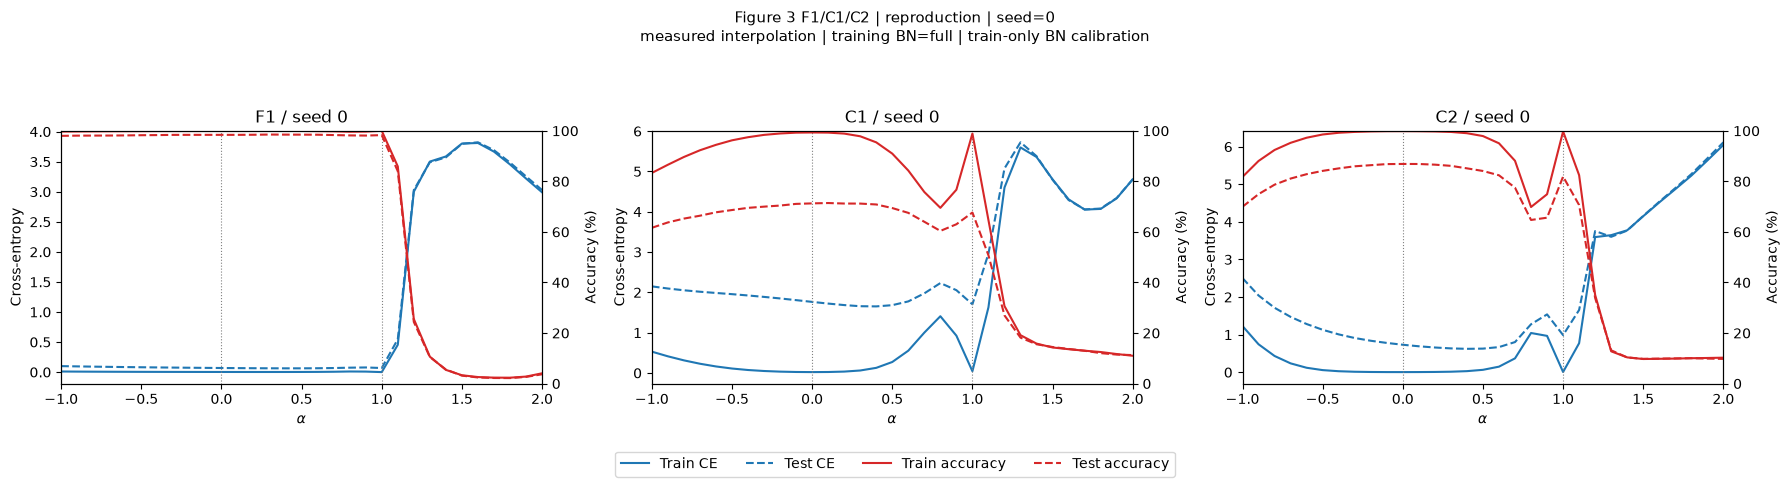

PosixPath('/home/NAS/yangc21/cs6362/paper2_figure3_outputs_v2/reproduction/plots/figure3_F1_C1_C2_seed_0.png')

In [10]:
def validate_saved_plot_inputs(name, seed, cfg):
    """Validate persisted provenance without accessing or downloading datasets."""
    directory = Path(cfg.root_output) / cfg.mode / 'interpolation'
    manifest_path = directory / f'{name}_seed_{seed}_manifest.json'
    if not manifest_path.exists():
        raise RuntimeError('A measured curve needs its provenance manifest before plotting.')
    manifest = json.loads(manifest_path.read_text())
    expected = {
        'implementation_version': cfg.implementation_version,
        'mode': cfg.mode, 'name': name, 'seed': int(seed),
        'alpha_grid': alpha_grid(cfg),
        'bn_strategy': 'train_only_reset_cumulative_batch_moments_dropout_off_v2',
        'bn_calibration_batch': int(cfg.bn_calibration_batch),
        'eval_batch': int(cfg.eval_batch),
        'endpoint_atol': cfg.endpoint_atol, 'endpoint_rtol': cfg.endpoint_rtol,
    }
    if any(manifest.get(key) != value for key, value in expected.items()):
        raise RuntimeError('Saved curve protocol differs from this configuration. Rerun interpolation in a compatible output root.')
    endpoints = {}
    for regime in ('SB', 'LB'):
        path = run_directory(name, seed, regime, cfg) / 'endpoint.pt'
        ckpt = load_own_checkpoint(path)
        digest = model_state_hash(ckpt['model_state'])
        if (digest != ckpt.get('model_state_hash') or
                digest != manifest.get(f'endpoint_{regime}_state_hash') or
                ckpt['signature'] != manifest.get(f'endpoint_{regime}_signature') or
                int(ckpt['selected_epoch']) != manifest.get(f'endpoint_{regime}_epoch')):
            raise RuntimeError('Saved interpolation refers to different endpoint content. Do not plot stale curves.')
        sig = ckpt['signature']
        settings = {
            'training_batch_mode': cfg.training_batch_mode,
            'lr': cfg.lr, 'betas': list(cfg.betas), 'eps': cfg.eps,
            'weight_decay': cfg.weight_decay,
            'max_epochs': cfg.smoke_max_epochs if cfg.mode == 'smoke' else cfg.max_epochs,
            'patience': cfg.patience, 'min_delta': cfg.min_delta,
            'min_epochs': cfg.min_epochs,
            'physical_microbatch_cap': cfg.microbatch_cap if cfg.training_batch_mode == 'microbatch' else None,
        }
        if any(sig.get(key) != value for key, value in settings.items()):
            raise RuntimeError('Saved training protocol differs from the current configuration.')
        if (sig['train_dataset'] != manifest['train_data_identity'] or
                sig['test_dataset'] != manifest['test_data_identity']):
            raise RuntimeError('Curve and endpoint dataset identities disagree.')
        endpoints[regime] = ckpt
    frame = pd.read_csv(directory / f'{name}_seed_{seed}.csv')
    records = _validate_curve_records(
        frame, alpha_grid(cfg), name, seed,
        range(manifest['train_data_identity']['examples']),
        range(manifest['test_data_identity']['examples']),
        endpoints['SB'], endpoints['LB'])
    if len(records) == len(alpha_grid(cfg)):
        check_file = directory / f'{name}_seed_{seed}_endpoint_checks.csv'
        if not check_file.exists():
            raise RuntimeError('Complete curves require their independent endpoint-check table.')
        checks = pd.read_csv(check_file)
        if len(checks) != 8 or not checks['same_policy_check_passed'].eq(True).all():
            raise RuntimeError('Independent endpoint-check table is incomplete or failed.')
        for item in checks.to_dict('records'):
            row = next(r for r in records if r['alpha'] == item['alpha'])
            value = float(row[f'{item["split"]}_{item["metric"]}'])
            if not math.isclose(value, float(item['interpolation_endpoint']),
                                abs_tol=cfg.endpoint_atol, rel_tol=cfg.endpoint_rtol):
                raise RuntimeError('Curve endpoints differ from their verified metric table.')
    print('Plotting saved measured metrics with verified endpoint hashes:', name, seed)


def plot_panel(model_name, seed, cfg=CFG, ax=None):
    path = Path(cfg.root_output) / cfg.mode / 'interpolation' / f'{model_name}_seed_{seed}.csv'
    if not path.exists():
        print('No measured CSV for:', model_name, seed, '(skipping)')
        return None
    validate_saved_plot_inputs(model_name, seed, cfg)
    data = pd.read_csv(path).sort_values('alpha_index')
    is_complete = len(data) == len(alpha_grid(cfg)) and np.allclose(
        data['alpha'].to_numpy(), np.asarray(alpha_grid(cfg)))
    if ax is None: _, ax = plt.subplots(figsize=(7, 4.5))
    ax2 = ax.twinx()
    ax.plot(data.alpha, data.train_loss, '-', color='tab:blue', label='Train CE')
    ax.plot(data.alpha, data.test_loss, '--', color='tab:blue', label='Test CE')
    ax2.plot(data.alpha, data.train_accuracy_pct, '-', color='tab:red', label='Train accuracy')
    ax2.plot(data.alpha, data.test_accuracy_pct, '--', color='tab:red', label='Test accuracy')
    ax.set(xlim=(-1,2), xlabel=r'$\alpha$', ylabel='Cross-entropy')
    ax2.set(ylabel='Accuracy (%)', ylim=(0, 100))
    ax.axvline(0, lw=0.8, ls=':', color='gray')
    ax.axvline(1, lw=0.8, ls=':', color='gray')
    ax.set_title(f'{model_name} / seed {seed}' + ('' if is_complete else ' (INCOMPLETE)'))
    if not is_complete: print('WARNING incomplete interpolation:', path)
    return ax, ax2


def plot_figure3(seed=0, cfg=CFG):
    available = [m for m in cfg.models if
        (Path(cfg.root_output) / cfg.mode / 'interpolation' / f'{m}_seed_{seed}.csv').exists()]
    if not available:
        print('No measured curves available; no plot created.')
        return None
    fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 4.7), squeeze=False)
    for i, name in enumerate(available):
        result = plot_panel(name, seed, cfg, axes[0, i])
        if result is None: continue
    from matplotlib.lines import Line2D
    legend = [Line2D([0], [0], color='tab:blue', ls='-', label='Train CE'),
              Line2D([0], [0], color='tab:blue', ls='--', label='Test CE'),
              Line2D([0], [0], color='tab:red', ls='-', label='Train accuracy'),
              Line2D([0], [0], color='tab:red', ls='--', label='Test accuracy')]
    fig.legend(handles=legend, loc='lower center', ncol=4, bbox_to_anchor=(0.5,-0.03))
    fig.suptitle(f'Figure 3 F1/C1/C2 | {cfg.mode} | seed={seed}\n'
                 f'measured interpolation | training BN={cfg.training_batch_mode} | train-only BN calibration', fontsize=11)
    fig.tight_layout(rect=(0, 0.06, 1, 0.91))
    out = Path(cfg.root_output) / cfg.mode / 'plots'
    out.mkdir(parents=True, exist_ok=True)
    file = out / f'figure3_F1_C1_C2_seed_{seed}.png'
    fig.savefig(file, dpi=180, bbox_inches='tight')
    print('Saved figure:', file)
    plt.show()
    return file

# Rendering does nothing without actual metrics.
plot_figure3(seed=CFG.seeds[0], cfg=CFG)

## 11. GPU execution guide and revision checks

1. Run All with the defaults to inspect model shapes and synthetic interpolation checks. Both execution flags remain False. No datasets are accessed.
2. Stage official MNIST and CIFAR-10 under `CFG.root_data`, or explicitly enable `download_datasets`. Keep this separate from author-code access. The existing Paper1 CIFAR-10 cache can be reused by setting `DATA_ROOT` to its root; Paper2 uses original32×32 images, not Paper1's crop/whitening.
3. In the configuration cell, select smoke mode, seed0, and set **both** `RUN_TRAINING=True` and `RUN_INTERPOLATION=True`. Execute through a real Jupyter kernel in a Slurm GPU job, saving the executed notebook with nbclient/nbconvert. All six smoke endpoints and the seven-point curves should finish. The paper datasets are required for this smoke step.
4. Check endpoint metrics, contiguous training history, `gpu_memory_preflight.csv`, and `interpolation/*_endpoint_checks.csv`. Same-policy endpoint checks must pass. Empty or incomplete curves must not be reported as full reproduction results.
5. For full data, set `CFG=replace(Config(), mode='reproduction', seeds=(0,))` in the configuration cell, keep `training_batch_mode='full'`, and enable both execution flags. Rerun all definitions after editing configuration. Full reproduction requires CUDA. GPU preflight checks each requested architecture's LB step before training any endpoints. On OOM the run stops and does not change the experiment silently.
6. If sufficient GPU memory is unavailable, explicitly configure the microbatch alternative in a **new output root** and report its BN departure. Do not relabel it as an equivalent full-BN experiment. A changed budget, dataset split or batch mode cannot reuse incompatible checkpoints.
7. Actual outputs are produced only by cell execution. Save the executed `.ipynb`, not just the terminal log; `%run` alone does not write outputs back to the source notebook. Keep training/interpolation results under the v2 output tree and retain native text/table/figure cell outputs.
8. Plots validate the saved manifest and current checkpoint content without downloading or rereading datasets. They show the recorded dataset identities from that manifest; rerun interpolation if you intend to evaluate different data.

**Checks performed during this revision:** default non-training execution; same-init full versus microbatch BN forward counts; tiny synthetic training with final-epoch recovery, interruption repair and nonfinite refusal; content-sensitive training signatures; complete/partial interpolation cache checks; same-epoch changed-weight rejection; same-policy alpha0/1 metric agreement. These are software validations on temporary synthetic data, not MNIST/CIFAR-10 results. Full GPU training and capacity preflight have not been run here.

Preserve the LLM chat link and Phase2 findings. Make a good-faith Phase3 attempt and commit it before consulting author code in optional Phase4. Keep one-dimensional geometry and single-seed limitations in the report.
